In [ ]:
Name Rohan Prakash Wayal
Roll no: 68
Problem Statement:- Implement K-Means and Hierarchical Clustering techniques. Use the Elbow Method and Dendrogram to determine the optimal number of clusters and analyze the generated clusters using a real-world dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Dataset Shape:', df.shape)
df.head()

Dataset Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
('Dataset Information:')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [6]:
('\nStatistical Summary:')
display(df.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
('\nMissing Values:')
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

X_scaled = pd.DataFrame(X_scaled, columns=df.columns)
X_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


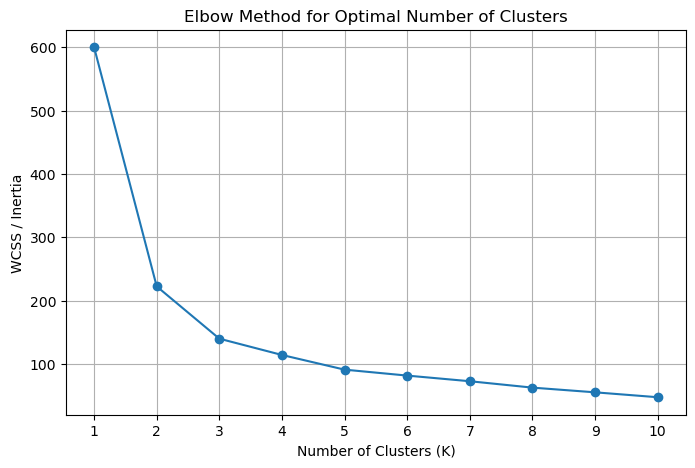

In [9]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans['KMeans_Cluster'] = kmeans_labels

display(df_kmeans.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),KMeans_Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


In [11]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
display(centers)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


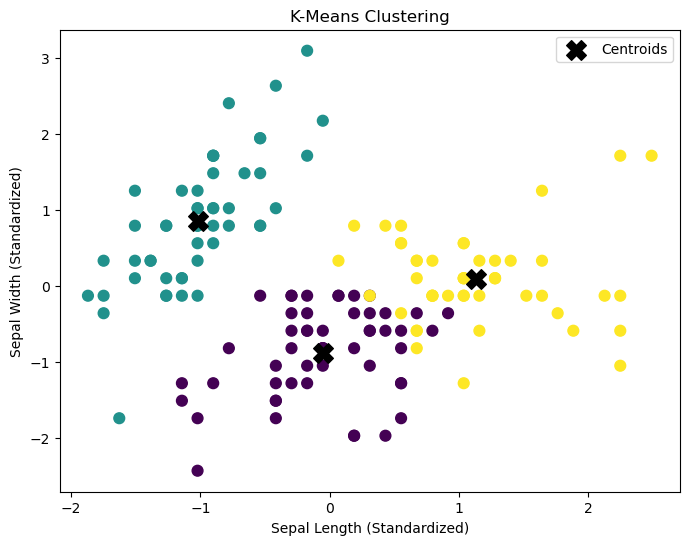

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], c=kmeans_labels, cmap='viridis', s=60)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker='X', s=200, color='black', label='Centroids')
plt.xlabel('Sepal Length (Standardized)')
plt.ylabel('Sepal Width (Standardized)')
plt.title('K-Means Clustering')
plt.legend()
plt.show()

In [13]:
cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()
silhouette_kmeans = silhouette_score(X_scaled, kmeans_labels)

('K-Means Cluster Sizes:')

'K-Means Cluster Sizes:'

In [14]:
(cluster_counts)

0    53
1    50
2    47
Name: count, dtype: int64

In [15]:
(f'K-Means Silhouette Score: {silhouette_kmeans:.4f}')

'K-Means Silhouette Score: 0.4599'

In [16]:
linked = linkage(X_scaled, method='ward')
('Linkage Matrix Shape:', linked.shape)

('Linkage Matrix Shape:', (149, 4))

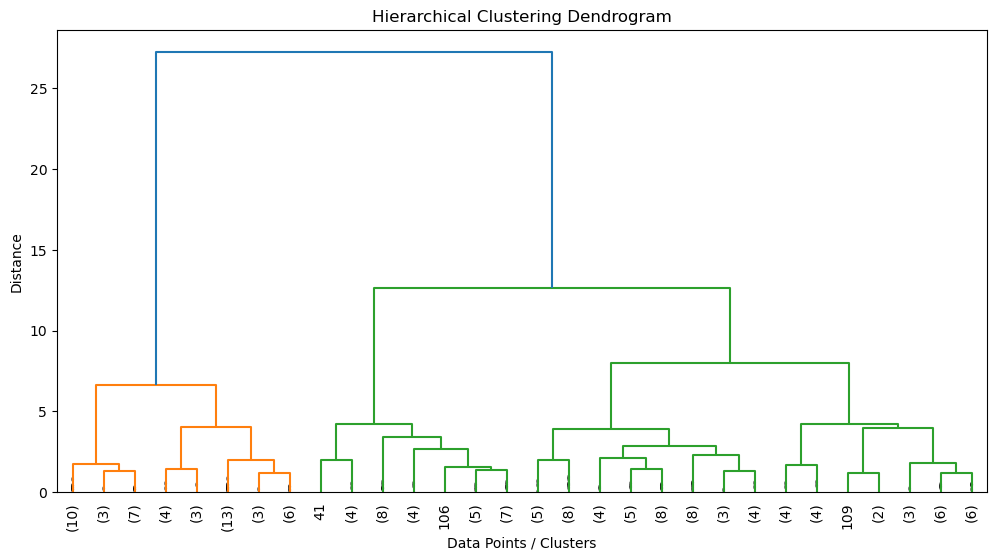

In [17]:
plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode='lastp', p=30,
           leaf_rotation=90, leaf_font_size=10,
           show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points / Clusters')
plt.ylabel('Distance')
plt.show()

In [18]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical['Hierarchical_Cluster'] = hierarchical_labels

display(df_hierarchical.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Hierarchical_Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


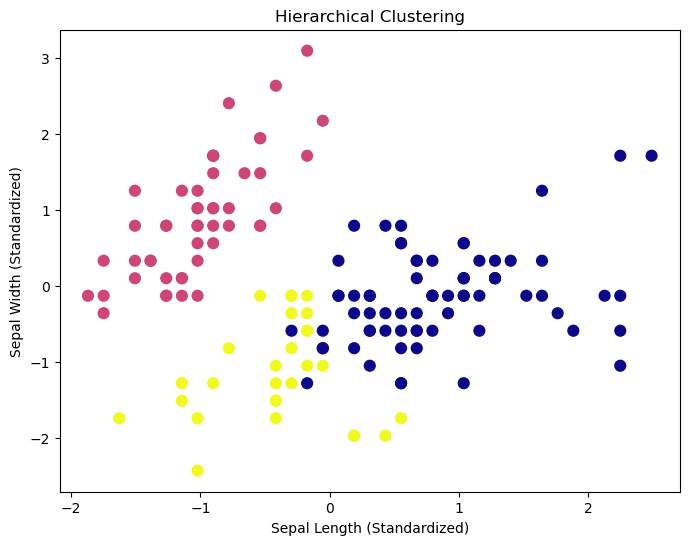

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1],
            c=hierarchical_labels, cmap='plasma', s=60)
plt.xlabel('Sepal Length (Standardized)')
plt.ylabel('Sepal Width (Standardized)')
plt.title('Hierarchical Clustering')
plt.show()

In [20]:
hierarchical_counts = pd.Series(hierarchical_labels).value_counts().sort_index()
silhouette_hierarchical = silhouette_score(X_scaled, hierarchical_labels)

print('Hierarchical Cluster Sizes:')
print(hierarchical_counts)

Hierarchical Cluster Sizes:
0    71
1    49
2    30
Name: count, dtype: int64


In [21]:
(f'Hierarchical Silhouette Score: {silhouette_hierarchical:.4f}')

'Hierarchical Silhouette Score: 0.4467'

In [22]:
print('K-Means Cluster Analysis:')
display(df_kmeans.groupby('KMeans_Cluster').mean(numeric_only=True))

K-Means Cluster Analysis:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
KMeans_Cluster,,,,
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.428000,1.462000,0.246000
2,6.780851,3.095745,5.510638,1.972340


In [23]:
print('Hierarchical Cluster Analysis:')
display(df_hierarchical.groupby('Hierarchical_Cluster').mean(numeric_only=True))

Hierarchical Cluster Analysis:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Hierarchical_Cluster,,,,
0,6.546479,2.992958,5.267606,1.854930
1,5.016327,3.451020,1.465306,0.244898
2,5.530000,2.566667,3.930000,1.206667


In [24]:
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical Clustering'],
    'Number of Clusters': [3, 3],
    'Silhouette Score': [silhouette_kmeans, silhouette_hierarchical]
})

display(comparison)

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.459948
1,Hierarchical Clustering,3,0.446689


In [25]:
final_df = df.copy()
final_df['KMeans_Cluster'] = kmeans_labels
final_df['Hierarchical_Cluster'] = hierarchical_labels

display(final_df.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),KMeans_Cluster,Hierarchical_Cluster
0,5.1,3.5,1.4,0.2,1,1
1,4.9,3.0,1.4,0.2,1,1
2,4.7,3.2,1.3,0.2,1,1
3,4.6,3.1,1.5,0.2,1,1
4,5.0,3.6,1.4,0.2,1,1
5,5.4,3.9,1.7,0.4,1,1
6,4.6,3.4,1.4,0.3,1,1
7,5.0,3.4,1.5,0.2,1,1
8,4.4,2.9,1.4,0.2,1,1
9,4.9,3.1,1.5,0.1,1,1
